In [ ]:
def bubbleSort(arr):
    for i in range(len(arr)-1):
        changed = False
        for j in range(len(arr)-1-i):
            if arr[j] > arr[j+1]:
                changed = True
                arr[j], arr[j+1] = arr[j+1], arr[j]
        print(arr)
        if not changed:
            break
    return arr
    
a = [1, 1, 2, 3, 4, 5, 6, 9]
bubbleSort(a)

[1, 1, 2, 3, 4, 5, 6, 9]


[1, 1, 2, 3, 4, 5, 6, 9]

In [7]:
a = 10
b = 5

b = a+b
a = b-a
b = b-a
print(a, b)

5 10


In [6]:
def selectionSort(arr):
    for i in range(len(arr)-1):
        curind = i
        for j in range(i+1, len(arr)):
            if arr[curind] > arr[j]:
                curind = j
        arr[i], arr[curind] = arr[curind], arr[i]
        print(arr)
    return arr

a = [1, 1, 2, 3, 4, 5, 6, 9]
selectionSort(a)

[1, 1, 2, 3, 4, 5, 6, 9]
[1, 1, 2, 3, 4, 5, 6, 9]
[1, 1, 2, 3, 4, 5, 6, 9]
[1, 1, 2, 3, 4, 5, 6, 9]
[1, 1, 2, 3, 4, 5, 6, 9]
[1, 1, 2, 3, 4, 5, 6, 9]
[1, 1, 2, 3, 4, 5, 6, 9]


[1, 1, 2, 3, 4, 5, 6, 9]

In [17]:
def insertionSort(arr):
    def findPositionLinear(arr, elem):
        cnt = 0
        for i in range(len(arr)):
            cnt += 1
            if arr[i] > elem:
                return i, cnt
        return i+1, cnt
            
    def findPositionBinary(arr, elem):
        left = 0
        right = len(arr) - 1
        cnt = 0
        while left <= right:
            cnt += 1
            mid = (left + right) // 2
            if arr[mid] >= elem and (mid == 0 or arr[mid-1] <= elem):
                return mid, cnt
            elif arr[mid] < elem:
                left = mid + 1
            else:
                right = mid - 1
        return len(arr), cnt

    cnt  = 0
    for i in range(1, len(arr)):
        new_index, c = findPositionBinary(arr[:i], arr[i])
        cnt += c
        curval = arr[i]
        for j in range(i, new_index, -1):
            arr[j] = arr[j-1]
            cnt += 1
        arr[new_index] = curval
    return arr, cnt 

a = [3, 1, 1, 2, 4, 6, 5, 9, 0]
insertionSort(a)

([0, 1, 1, 2, 3, 4, 5, 6, 9], 32)

In [10]:
import numpy as np

lens = [10, 20, 50, 100, 1000, 5000, 10000]
cnts = []
for l in lens:
    a = np.random.uniform(0, 10000, l)
    a, cnt = insertionSort(a)
    cnts.append(cnt)

In [18]:
import numpy as np

lens = [10, 20, 50, 100, 1000, 5000, 10000]
cnts_bin = []
for l in lens:
    a = np.random.uniform(0, 10000, l)
    a, cnt = insertionSort(a)
    cnts_bin.append(cnt)

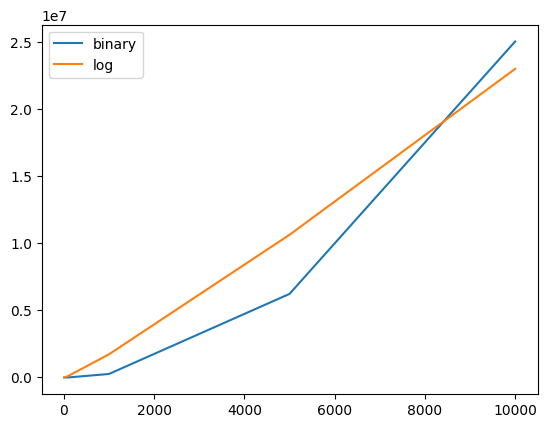

In [32]:
from matplotlib import pyplot as plt

# plt.plot(lens, cnts, label='linear')
plt.plot(lens, cnts_bin, label='binary')
# plt.plot(lens, np.power(lens, 2)/4, label='power_2')
plt.plot(lens, np.log(lens)*np.array(lens)*250, label='log')
plt.legend()

In [34]:
a = [1, 3, 5, 7]
b = [2, 4, 6, 8, 10, 12, 14, 16, 18]

def merge(arr1, arr2):
    ind1 = 0
    ind2 = 0
    final = []
    cnt = 0
    while ind1 < len(arr1) and ind2 < len(arr2):
        cnt += 1
        if arr1[ind1] >= arr2[ind2]:
            final.append(arr2[ind2])
            ind2 += 1
        else:
            final.append(arr1[ind1])
            ind1 += 1
    final += arr1[ind1:] + arr2[ind2:]
    cnt += len(arr1[ind1:] + arr2[ind2:])
    return final, cnt

merge(a, b)

([1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 14, 16, 18], 13)

In [37]:
def mergeSort(arr):
    cnt = 1
    if len(arr) == 1:
        return arr, 1
    arr_l, cl = mergeSort(arr[:len(arr)//2])
    arr_r, cr = mergeSort(arr[len(arr)//2:])
    cnt += cl + cr
    arr, c = merge(arr_l, arr_r)
    return arr, cnt + c

In [38]:
a = [3, 1, 1, 2, 4, 6, 5, 9, 0]
mergeSort(a)

([0, 1, 1, 2, 3, 4, 5, 6, 9], 46)

In [39]:
import numpy as np

lens = [10, 20, 50, 100, 1000, 5000, 10000]
cnts = []
for l in lens:
    a = np.random.uniform(0, 10000, l)
    a, cnt = mergeSort(a)
    cnts.append(cnt)

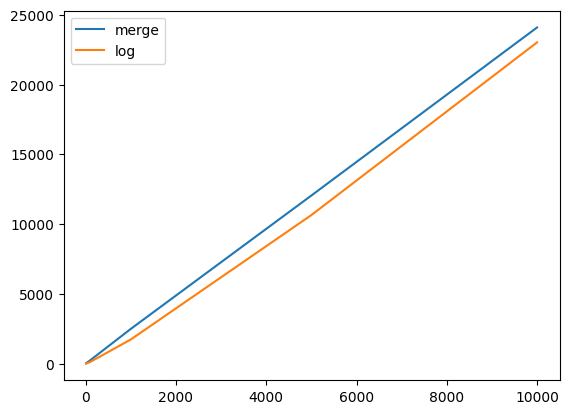

In [42]:
from matplotlib import pyplot as plt

plt.plot(lens, cnts, label='merge')
# plt.plot(lens, np.power(lens, 2)/4, label='power_2')
plt.plot(lens, np.log(lens)*np.array(lens)/4, label='log')
plt.legend()

In [43]:
a = [1,2]
a[2:]

[]

In [48]:
np.random.uniform(0, 10, 1)[0]

3.2025140215245926

In [123]:
def selectRandomPivot(arr):
    return np.random.randint(0, len(arr), 1)[0]
def selectMidPivot(arr):
    return len(arr)//2
def selectLastPivot(arr):
    return len(arr)-1
def selectFirstPivot(arr):
    return 0
def selectMinPivot(arr):
    return np.argmin(arr)
def selectMaxPivot(arr):
    return np.argmax(arr)
def medianOfThree(arr):
    if arr[0] > arr[-1]:
        if arr[0] > arr[len(arr)//2]:
            if arr[-1] > arr[len(arr)//2]:
                return len(arr)-1
            else:
                return len(arr)//2
        else: 
            return 0
    elif arr[-1] > arr[len(arr)//2]:
        if arr[0] > arr[len(arr)//2]:
            return 0
        else:
            return len(arr)//2
    else:
        return len(arr)-1
    
def selectMedian(arr):
    sr = sum(arr) / len(arr)
    delta = float("inf")
    med_pos = None
    for i in range(len(arr)):
        if abs(arr[i] - sr) < delta:
            delta = abs(arr[i] - sr)
            med_pos = i
    return med_pos

def quickSort(arr, pivotSelection):
    cnt = 1
    if len(arr) <= 1:
         return arr, 1
    pivot = pivotSelection(arr)
    arr[-1], arr[pivot] = arr[pivot], arr[-1]
    left = 0
    right = len(arr) - 2
    while left <= right and right >= 0:
        cnt += 1
        while left <= right and arr[left] < arr[-1]:
            cnt += 1
            left += 1
        while left <= right and arr[right] >= arr[-1]:
            cnt += 1
            right -= 1
        if left <= right:
            arr[left], arr[right] = arr[right], arr[left]
        else:
            arr[-1], arr[left] = arr[left], arr[-1]
    arr[:left], cl = quickSort(arr[:left], pivotSelection)
    arr[left+1:], cr = quickSort(arr[left+1:], pivotSelection)
    return arr, cnt + cl + cr

In [125]:
selectMedian([3, 2, 2])

1

In [114]:
a = [3, 1, 1, 2, 4, 6, 5, 9, 0]
quickSort(a, selectRandomPivot)

([0, 1, 1, 2, 3, 4, 5, 6, 9], 37)

In [131]:
import numpy as np

lens = [10, 20, 50, 100, 1000, 5000]#, 10000]
cnts_random = []
cnts_mid = []
cnts_last = []
cnts_first = []
cnts_min = []
cnts_max = []
cnts_median = []
cnts_median_full = []
for l in lens:
    a = np.random.uniform(0, 10000, l)
    _, cnt = quickSort(a, selectRandomPivot)
    cnts_random.append(cnt)
    _, cnt = quickSort(a, selectMidPivot)
    cnts_mid.append(cnt)
    _, cnt = quickSort(a, selectLastPivot)
    cnts_last.append(cnt)
    _, cnt = quickSort(a, selectMedian)
    cnts_median_full.append(cnt)
    _, cnt = quickSort(a, medianOfThree)
    cnts_median.append(cnt)
    # _, cnt = quickSort(a, selectMaxPivot)
    # cnts_max.append(cnt)

RecursionError: maximum recursion depth exceeded while calling a Python object

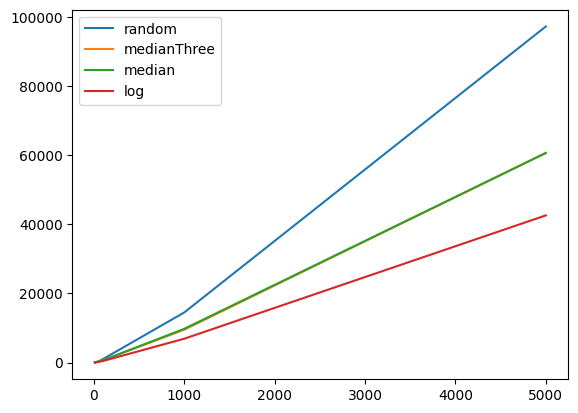

In [130]:
from matplotlib import pyplot as plt

plt.plot(lens, cnts_random, label='random')
# plt.plot(lens, cnts_mid, label='mid')
# plt.plot(lens, cnts_last, label='last')
# plt.plot(lens, cnts_first, label='first')
plt.plot(lens, cnts_median, label='medianThree')
plt.plot(lens, cnts_median_full, label='median')
# plt.plot(lens, np.power(lens, 2)/4, label='power_2')
plt.plot(lens, np.log(lens)*np.array(lens), label='log')
plt.legend()